# Topic Modeling in NLP: Complete Notes + Methods + Google Colab Practicals

**Audience:** Undergraduate NLP / AI-ML students  
**Level:** Introductory to intermediate  
**Runtime:** Google Colab (Python 3)

## Learning outcomes
By the end, you should be able to:
1. Explain topic modeling and distinguish it from text classification.
2. Preprocess a text corpus and create numerical representations.
3. Implement **LDA, NMF, and BERTopic** (BERTopic section is optional and may require extra installation/runtime).
4. inspect topic words, document-topic distributions, and visualizations.
5. Compare methods, understand limitations, and design a small experiment.

> **Important:** Topic models discover statistical or semantic patterns. They do not automatically know the correct human meaning of a topic. Interpret top words and representative documents, then assign topic labels yourself.

## 1. What is topic modeling?

Topic modeling is an **unsupervised NLP** approach that identifies recurring themes in a collection of documents without requiring pre-assigned topic labels.

**Example uses**
- Group student feedback into teaching, assessment, infrastructure, and placements.
- Explore themes in research-paper abstracts.
- Discover themes in customer reviews or news articles.
- Summarize large collections of documents for exploratory analysis.

### Topic modeling vs. text classification
| Topic modeling | Text classification |
|---|---|
| Usually unsupervised | Usually supervised |
| Topic labels are not given in advance | Training examples have known labels |
| Discovers patterns in a corpus | Predicts predefined categories |
| Example: discover themes in feedback | Example: classify a comment as a complaint |

### Core terminology
- **Corpus:** Collection of documents.
- **Document:** One text item, such as a sentence, review, or article.
- **Token:** A word or text unit.
- **Vocabulary:** Unique terms retained after preprocessing.
- **Document-term matrix (DTM):** Rows are documents; columns are terms; values are counts or weights.
- **Topic:** A group/distribution of words that tend to occur together.
- **Document-topic distribution:** Estimated proportion/probability of each topic in a document.
- **Top words:** Words with high weights/probabilities in a topic.
- **Topic coherence:** A measure intended to reflect how interpretable/co-occurring a topic's words are.
- **Dominant topic:** Topic with the largest estimated document-topic weight. This simplifies a mixture into one label and may hide ambiguity.

## 2. Common topic modeling methods

| Method | Main idea | Strengths | Limitations |
|---|---|---|---|
| **LDA** (Latent Dirichlet Allocation) | Probabilistic model of document-topic and topic-word distributions | Interpretable; classic baseline | Bag-of-words; topic count chosen beforehand; short texts can be difficult |
| **NMF** (Non-negative Matrix Factorization) | Factorizes a non-negative document-term/TF-IDF matrix into document-topic and topic-term factors | Often effective with TF-IDF; relatively straightforward | Topic count chosen beforehand; not a probabilistic generative model |
| **LSA/LSI** (Latent Semantic Analysis/Indexing) | Uses truncated SVD on a term-document matrix | Efficient dimensionality reduction; useful baseline | Components can contain positive and negative weights; interpretation may be less intuitive |
| **pLSA** (Probabilistic Latent Semantic Analysis) | Models word occurrence through latent topics | Historical probabilistic approach | Document parameters can grow with corpus; less common in current basic workflows |
| **BERTopic** | Usually transformer embeddings + dimensionality reduction + clustering + class-based TF-IDF topic representation | Captures semantic similarity; can group paraphrases | More computationally expensive; results depend on embedding/clustering settings |
| **Embedding + clustering** | Create sentence/document embeddings, cluster them, then describe clusters | Flexible and semantically informed | Clusters are not inherently word-probability topics; requires cluster interpretation |
| **Neural topic models** | Learn latent topics using neural encoders/decoders | Flexible representations; research-oriented | More complexity, tuning, and evaluation effort |

**Which should you start with?** Learn LDA first, compare it with NMF, then explore BERTopic for semantic topic discovery. No method is best for every corpus.

## 3. Prepare a teaching dataset

This small synthetic dataset includes AI/ML, infrastructure, and career-related comments. It is useful for learning code, **not for making research claims**. Add a larger real dataset for a serious study.

In [1]:
documents = [
    "Machine learning uses algorithms to learn from data.",
    "Deep learning uses neural networks for artificial intelligence.",
    "Python is widely used for machine learning and data science.",
    "Neural networks and deep learning improve image recognition.",
    "Artificial intelligence supports prediction and automation.",
    "Data science uses statistics and machine learning techniques.",
    "Students need better classrooms and laboratory facilities.",
    "The college needs projectors and modern computer laboratories.",
    "Good infrastructure improves the student learning experience.",
    "Libraries should provide more books, computers, and study spaces.",
    "Students are looking for internships and placement opportunities.",
    "Companies recruit students with programming and technical skills.",
    "Internships provide practical experience and career development.",
    "Career guidance helps students prepare for technical interviews.",
    "The exam schedule should be announced early.",
    "Assessment feedback helps students understand their mistakes.",
    "Teachers should explain difficult concepts with practical examples.",
    "Project-based learning helps students apply programming skills."
]

print("Number of documents:", len(documents))
for i, doc in enumerate(documents, start=1):
    print(f"{i}. {doc}")

Number of documents: 18
1. Machine learning uses algorithms to learn from data.
2. Deep learning uses neural networks for artificial intelligence.
3. Python is widely used for machine learning and data science.
4. Neural networks and deep learning improve image recognition.
5. Artificial intelligence supports prediction and automation.
6. Data science uses statistics and machine learning techniques.
7. Students need better classrooms and laboratory facilities.
8. The college needs projectors and modern computer laboratories.
9. Good infrastructure improves the student learning experience.
10. Libraries should provide more books, computers, and study spaces.
11. Students are looking for internships and placement opportunities.
12. Companies recruit students with programming and technical skills.
13. Internships provide practical experience and career development.
14. Career guidance helps students prepare for technical interviews.
15. The exam schedule should be announced early.
16. Ass

## 4. Preprocessing notes

Typical steps may include:
1. Normalize case.
2. Remove or normalize punctuation and extra whitespace.
3. Tokenize text.
4. Remove stop words where appropriate.
5. Consider lemmatization or stemming if useful.
6. Build features.

**Caution:** Do not automatically remove every frequent word or every short word. Terms such as “not” can change sentiment; domain-specific terms may be important. Preserve phrases like “machine learning” when appropriate using n-grams. Preprocessing should fit the task and language.

In [2]:
import re

def basic_clean(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

clean_documents = [basic_clean(doc) for doc in documents]
print("Before:", documents[0])
print("After: ", clean_documents[0])

Before: Machine learning uses algorithms to learn from data.
After:  machine learning uses algorithms to learn from data


## 5. Create count and TF-IDF features

- **CountVectorizer:** represents each document by term counts.
- **TF-IDF:** gives more weight to terms frequent in a document but less common across the corpus.
- LDA is commonly used with count data.
- NMF and LSA often work well with TF-IDF representations.

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

count_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=1
)
X_count = count_vectorizer.fit_transform(clean_documents)

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=1
)
X_tfidf = tfidf_vectorizer.fit_transform(clean_documents)

print("Count matrix shape:", X_count.shape)
print("TF-IDF matrix shape:", X_tfidf.shape)
print("Example vocabulary:", count_vectorizer.get_feature_names_out()[:25])

Count matrix shape: (18, 162)
TF-IDF matrix shape: (18, 162)
Example vocabulary: ['algorithms' 'algorithms learn' 'announced' 'announced early' 'apply'
 'apply programming' 'artificial' 'artificial intelligence' 'assessment'
 'assessment feedback' 'automation' 'based' 'based learning' 'better'
 'better classrooms' 'books' 'books computers' 'career'
 'career development' 'career guidance' 'classrooms'
 'classrooms laboratory' 'college' 'college needs' 'companies']


## 6. Helper function: display top words

We will reuse this function for LDA, NMF, and LSA. Top words help interpret components but do not prove that a topic is meaningful.

In [4]:
def show_top_words(model, feature_names, n_words=10, method_name="Model"):
    print(f"\n===== {method_name}: top words =====")
    for topic_idx, component in enumerate(model.components_):
        top_indices = component.argsort()[-n_words:][::-1]
        words = [feature_names[i] for i in top_indices]
        print(f"Topic {topic_idx + 1}: " + ", ".join(words))

# Method 1 — LDA (Latent Dirichlet Allocation)

## 7. LDA concept and notes

LDA is a probabilistic generative topic model. At a high level:
- Each document has a mixture of topics.
- Each topic has a distribution over words.
- The model estimates these distributions from word counts.

A document may be, for example, 70% AI/ML and 30% teaching methods in the model's estimated topic mixture. These values are not ground-truth labels.

**Important parameters**
- `n_components`: number of topics requested.
- `max_iter`: maximum training iterations.
- `random_state`: seed for repeatability.
- `learning_method`: batch or online optimization strategy.

Choose the number of topics by comparing interpretability, coherence, stability, and usefulness for the task—not only by choosing the model with the most topics.

In [5]:
from sklearn.decomposition import LatentDirichletAllocation

n_topics_lda = 4
lda_model = LatentDirichletAllocation(
    n_components=n_topics_lda,
    max_iter=30,
    random_state=42,
    learning_method="batch"
)
lda_model.fit(X_count)

lda_terms = count_vectorizer.get_feature_names_out()
show_top_words(lda_model, lda_terms, n_words=10, method_name="LDA")


===== LDA: top words =====
Topic 1: artificial, intelligence, artificial intelligence, learning uses, learning, neural networks, neural, networks, deep, deep learning
Topic 2: machine, machine learning, data, helps, helps students, students, uses, learning, science, data science
Topic 3: learning, skills, programming, provide, experience, programming skills, project, learning helps, project based, apply
Topic 4: students, practical, internships, used, widely, learning data, python widely, python, used machine, widely used


## 8. LDA document-topic probabilities

`transform()` returns one topic-weight vector per document. For each document, the weights sum to approximately 1. The dominant topic is the largest weight, but inspect the full distribution when a document is mixed or ambiguous.

In [6]:
import pandas as pd
from IPython.display import display

lda_doc_topics = lda_model.transform(X_count)
lda_topic_cols = [f"LDA_Topic_{i+1}" for i in range(n_topics_lda)]

lda_results = pd.DataFrame(lda_doc_topics, columns=lda_topic_cols)
lda_results.insert(0, "Document", documents)
lda_results["Dominant_Topic"] = lda_doc_topics.argmax(axis=1) + 1

display(lda_results.round(3))

,Document,LDA_Topic_1,LDA_Topic_2,LDA_Topic_3,LDA_Topic_4,Dominant_Topic
0,Machine learning uses algorithms to learn from...,0.021,0.937,0.021,0.021,2
1,Deep learning uses neural networks for artific...,0.946,0.018,0.018,0.018,1
2,Python is widely used for machine learning and...,0.018,0.019,0.018,0.944,4
3,Neural networks and deep learning improve imag...,0.019,0.018,0.945,0.018,3
4,Artificial intelligence supports prediction an...,0.026,0.924,0.025,0.025,2
5,Data science uses statistics and machine learn...,0.018,0.946,0.018,0.018,2
6,Students need better classrooms and laboratory...,0.021,0.021,0.021,0.937,4
7,The college needs projectors and modern comput...,0.021,0.937,0.021,0.021,2
8,Good infrastructure improves the student learn...,0.021,0.021,0.937,0.021,3
9,"Libraries should provide more books, computers...",0.021,0.021,0.937,0.021,3


## 9. LDA visualization: dominant-topic counts

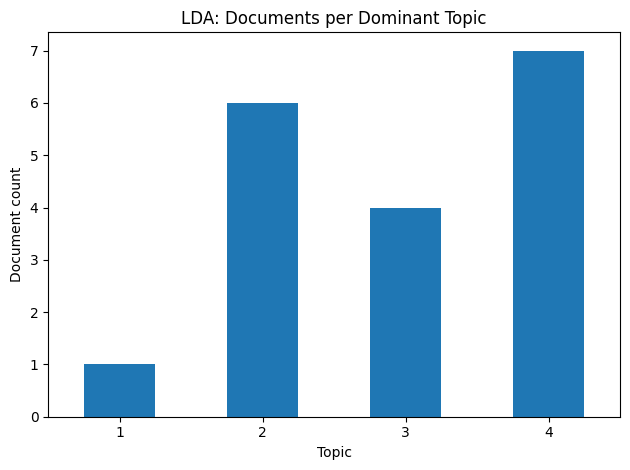

In [7]:
import matplotlib.pyplot as plt

lda_results["Dominant_Topic"].value_counts().sort_index().plot(kind="bar")
plt.title("LDA: Documents per Dominant Topic")
plt.xlabel("Topic")
plt.ylabel("Document count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Method 2 — NMF (Non-negative Matrix Factorization)

## 10. NMF concept and notes

NMF factorizes a non-negative feature matrix into two lower-dimensional matrices. Informally:
- one matrix represents how strongly documents relate to topics;
- the other represents how strongly terms relate to topics.

NMF is not the same as LDA and does not produce the same probabilistic interpretation. TF-IDF is a common input for NMF. Select the number of components and compare top words and document assignments.

In [8]:
from sklearn.decomposition import NMF

n_topics_nmf = 4
nmf_model = NMF(
    n_components=n_topics_nmf,
    init="nndsvda",
    random_state=42,
    max_iter=500
)
W_nmf = nmf_model.fit_transform(X_tfidf)
H_nmf = nmf_model.components_

tfidf_terms = tfidf_vectorizer.get_feature_names_out()
show_top_words(nmf_model, tfidf_terms, n_words=10, method_name="NMF")


===== NMF: top words =====
Topic 1: machine, machine learning, data, science, data science, learning, uses, statistics machine, science uses, uses statistics
Topic 2: students, helps students, helps, programming, skills, technical, project based, students apply, apply programming, learning helps
Topic 3: neural networks, neural, deep, networks, deep learning, artificial, intelligence, artificial intelligence, learning, networks artificial
Topic 4: provide, practical, internships, experience, provide practical, internships provide, practical experience, experience career, development, career development


## 11. NMF document-topic weights

NMF outputs non-negative factor weights. They are **not automatically probabilities** and generally do not sum to 1. For a simple comparison, choose the topic with the largest weight.

,Document,NMF_Topic_1,NMF_Topic_2,NMF_Topic_3,NMF_Topic_4,Dominant_Topic
0,Machine learning uses algorithms to learn from...,0.497,0.000,0.062,0.000,1
1,Deep learning uses neural networks for artific...,0.035,0.000,0.801,0.000,3
2,Python is widely used for machine learning and...,0.549,0.000,0.000,0.000,1
3,Neural networks and deep learning improve imag...,0.000,0.000,0.679,0.000,3
4,Artificial intelligence supports prediction an...,0.000,0.000,0.435,0.000,3
5,Data science uses statistics and machine learn...,0.586,0.000,0.000,0.000,1
6,Students need better classrooms and laboratory...,0.000,0.188,0.000,0.000,2
7,The college needs projectors and modern comput...,0.000,0.000,0.000,0.001,4
8,Good infrastructure improves the student learn...,0.050,0.000,0.042,0.343,4
9,"Libraries should provide more books, computers...",0.000,0.000,0.000,0.371,4


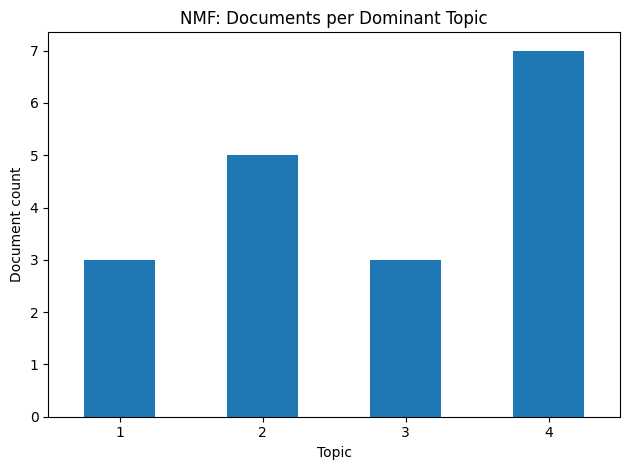

In [9]:
nmf_dominant = W_nmf.argmax(axis=1) + 1
nmf_results = pd.DataFrame(W_nmf, columns=[f"NMF_Topic_{i+1}" for i in range(n_topics_nmf)])
nmf_results.insert(0, "Document", documents)
nmf_results["Dominant_Topic"] = nmf_dominant
display(nmf_results.round(3))

nmf_results["Dominant_Topic"].value_counts().sort_index().plot(kind="bar")
plt.title("NMF: Documents per Dominant Topic")
plt.xlabel("Topic")
plt.ylabel("Document count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Method 3 — LSA / LSI (Latent Semantic Analysis)

## 12. LSA concept and notes

LSA applies truncated Singular Value Decomposition (SVD) to a term-document feature matrix. It finds latent dimensions that summarize patterns of term usage.

- It is often used for dimensionality reduction and semantic search.
- Components can contain positive and negative weights.
- It is not a probabilistic topic model like LDA.
- Component interpretation may be less direct than LDA or NMF.

We use TF-IDF features and inspect the largest positive-weight terms for a simple demonstration.

In [10]:
from sklearn.decomposition import TruncatedSVD

n_topics_lsa = 4
lsa_model = TruncatedSVD(n_components=n_topics_lsa, random_state=42)
X_lsa = lsa_model.fit_transform(X_tfidf)

show_top_words(lsa_model, tfidf_terms, n_words=10, method_name="LSA (largest positive weights)")
print("\nExplained variance ratio per component:")
print(lsa_model.explained_variance_ratio_.round(3))


===== LSA (largest positive weights): top words =====
Topic 1: learning, uses, data, machine learning, machine, learning uses, science, data science, neural networks, deep
Topic 2: students, helps students, helps, technical, skills, programming, career, assessment feedback, assessment, students understand
Topic 3: neural networks, neural, deep, networks, deep learning, artificial intelligence, intelligence, artificial, uses neural, networks artificial
Topic 4: provide, internships, experience, practical, provide practical, internships provide, practical experience, experience career, development, career development

Explained variance ratio per component:
[0.062 0.062 0.082 0.06 ]


# Method 4 — BERTopic (embedding-based topic modeling)

## 13. BERTopic concept and notes

BERTopic commonly combines:
1. Transformer-based document embeddings.
2. Dimensionality reduction (often UMAP).
3. Clustering (often HDBSCAN).
4. Class-based TF-IDF to describe clusters with representative words.

It can capture semantic similarity better than raw word-count methods for some tasks, but it can be slower and requires more dependencies. Some documents may be assigned to an outlier topic, commonly represented by `-1`.

**Optional Colab section:** Installation may take a few minutes and can fail if package versions or runtime resources change. If it fails, continue with LDA/NMF/LSA above.

In [11]:
# Optional: install BERTopic and its dependencies.
# Run this cell only if you want to try BERTopic.
%pip -q install bertopic

In [12]:
# Optional BERTopic training cell. Run after successful installation.
from bertopic import BERTopic

bertopic_model = BERTopic(language="english", verbose=False)
bertopic_topics, bertopic_probs = bertopic_model.fit_transform(documents)

print(bertopic_model.get_topic_info())
print("\nExample topic terms:")
for topic_id in sorted(set(bertopic_topics)):
    if topic_id != -1:
        print(f"Topic {topic_id}:", bertopic_model.get_topic(topic_id)[:10])

# Optional interactive visualizations (if supported by the runtime):
# bertopic_model.visualize_topics()
# bertopic_model.visualize_barchart(top_n_topics=10)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

   Topic  Count                          Name  \
0     -1     18  -1_and_learning_students_for   

                                      Representation  \
0  [and, learning, students, for, data, machine, ...   

                                 Representative_Docs  
0  [Deep learning uses neural networks for artifi...  

Example topic terms:


# Method 5 — Embeddings + clustering (conceptual alternative)

Instead of using word counts, encode each document as a dense semantic vector with a sentence-transformer model, then cluster the vectors (for example, with K-Means). Inspect the documents in each cluster and extract representative words or use a language model to help summarize them.

**Difference from BERTopic:** BERTopic packages a particular embedding + reduction + clustering + topic-description workflow. A custom embedding-clustering pipeline lets you choose each component yourself.

In [13]:
# Optional simple clustering baseline using TF-IDF + K-Means.
# This is clustering, not a probabilistic topic model.
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_tfidf)

cluster_results = pd.DataFrame({
    "Document": documents,
    "Cluster": cluster_labels
})
display(cluster_results.sort_values("Cluster"))

,Document,Cluster
6,Students need better classrooms and laboratory...,0
7,The college needs projectors and modern comput...,0
10,Students are looking for internships and place...,0
9,"Libraries should provide more books, computers...",0
12,Internships provide practical experience and c...,0
14,The exam schedule should be announced early.,0
16,Teachers should explain difficult concepts wit...,0
1,Deep learning uses neural networks for artific...,1
8,Good infrastructure improves the student learn...,1
4,Artificial intelligence supports prediction an...,1


# Method 6 — pLSA and neural topic models (theory notes)

## 14. pLSA (Probabilistic Latent Semantic Analysis)
pLSA models word occurrences using latent topics and document-specific topic mixtures. It is historically important and helped lead to LDA. A common limitation is that it does not provide LDA's same prior-based treatment of unseen documents; its document-specific parameters can grow with the training corpus.

## 15. Neural topic models
Neural approaches use neural networks, latent-variable models, variational autoencoders, or embedding-based representations to learn topic structure. They can be useful for research but often need more data, tuning, and careful evaluation. BERTopic is an embedding-and-clustering pipeline; it should not be confused with every neural generative topic model.

# 16. Comparing methods

Use this table as a starting point; real performance depends on corpus, language, preprocessing, and purpose.

| Criterion | LDA | NMF | LSA | BERTopic |
|---|---|---|---|---|
| Typical input | Count matrix | Often TF-IDF | Count or TF-IDF | Text + embeddings |
| Topic count | Set beforehand | Set beforehand | Set components | Can discover clusters; settings affect count |
| Probabilistic document-topic mixture | Yes | No | No | Not in the same sense as LDA |
| Semantic embeddings | No | No | No | Usually yes |
| Runtime | Low/moderate | Low/moderate | Low/moderate | Moderate/high |
| Interpretability | Top words + probabilities | Top words + weights | Component terms | Representative words/docs |
| Good first baseline? | Yes | Yes | Useful baseline | Good modern comparison |

## 17. Evaluating topic quality

There is no single metric that proves a topic model is good.

- **Human interpretability:** Can a reader understand a coherent theme from top words and example documents?
- **Topic coherence:** Do important words tend to co-occur in the corpus? Gensim provides common coherence measures such as `c_v` and `u_mass`.
- **Topic diversity:** Are topics repeating the same words or covering distinct themes?
- **Stability:** Do similar topics appear across different random seeds or samples?
- **Downstream usefulness:** Do topics help with the intended task, such as triaging feedback?

**Perplexity note:** LDA perplexity can help compare models under consistent settings, but lower perplexity does not necessarily mean more interpretable topics.

## 18. Optional LDA perplexity comparison

This experiment compares perplexity for different topic counts. Treat it as one diagnostic, not the only selection criterion.

,n_topics,perplexity
0,2,250.416106
1,3,278.838290
2,4,318.762052
3,5,334.504941


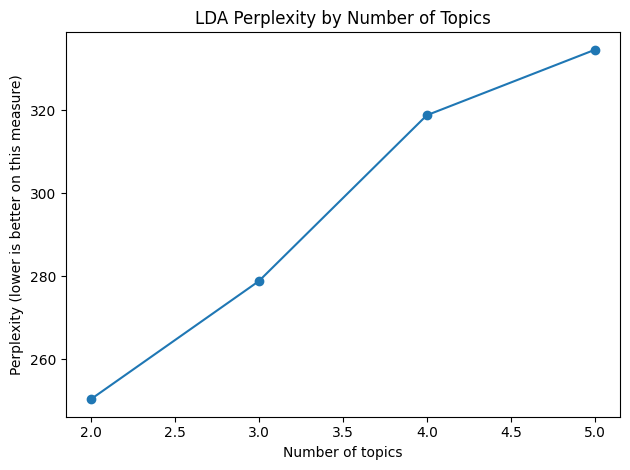

In [14]:
perplexity_rows = []
for k in [2, 3, 4, 5]:
    model = LatentDirichletAllocation(
        n_components=k,
        max_iter=20,
        random_state=42,
        learning_method="batch"
    )
    model.fit(X_count)
    perplexity_rows.append({
        "n_topics": k,
        "perplexity": model.perplexity(X_count)
    })

perplexity_df = pd.DataFrame(perplexity_rows)
display(perplexity_df)

plt.plot(perplexity_df["n_topics"], perplexity_df["perplexity"], marker="o")
plt.title("LDA Perplexity by Number of Topics")
plt.xlabel("Number of topics")
plt.ylabel("Perplexity (lower is better on this measure)")
plt.tight_layout()
plt.show()

# 19. Student lab tasks

1. Add 20–50 comments from a domain of your choice (use only data you are allowed to process).
2. Run LDA with 3, 4, 5, and 6 topics. Record the top 10 words for each.
3. Run NMF with the same topic counts and compare themes.
4. Inspect representative documents from each topic or cluster.
5. Identify topics that overlap or contain unrelated terms.
6. Test unigram features versus unigram + bigram features.
7. Write a short conclusion: which method was most useful for your corpus, and why?
8. Explain why topic IDs such as `Topic 1` are arbitrary and should be interpreted from words and documents.

## 20. Common mistakes and troubleshooting
- **Too few documents:** topic patterns may be unstable or uninformative.
- **Too many topics:** themes may fragment into near-duplicates.
- **Too few topics:** distinct themes may be merged.
- **Aggressive preprocessing:** important domain words or negation may be lost.
- **Misreading NMF weights as probabilities:** NMF weights are not inherently normalized probabilities.
- **Misreading BERTopic `-1`:** often indicates outlier documents, not a meaningful topic label.
- **Treating top words as ground truth:** always read example documents.
- **Comparing methods unfairly:** use the same corpus and document boundaries; document differences in preprocessing.
- **Ignoring privacy:** remove identifying or confidential data before uploading text to hosted notebooks.

## 21. Short glossary
- **Unsupervised learning:** Learns patterns without supplied target labels.
- **Tokenization:** Splitting text into tokens.
- **Stop words:** Frequent words often removed for a specific task.
- **N-gram:** Sequence of n tokens; a bigram contains two tokens.
- **TF-IDF:** Term-frequency/inverse-document-frequency weighting.
- **Latent:** Not directly observed; inferred from patterns.
- **Embedding:** Dense vector representation of text.
- **Clustering:** Grouping similar data points.
- **Outlier:** Item not assigned to a regular cluster.
- **Reproducibility:** Ability to repeat an experiment under the same conditions.

## 22. Further reading
- [scikit-learn: Latent Dirichlet Allocation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html)
- [scikit-learn: Topic extraction with NMF and LDA](https://scikit-learn.org/stable/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html)
- [scikit-learn: Non-negative Matrix Factorization](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html)
- [BERTopic documentation](https://maartengr.github.io/BERTopic/)

---
**End of notebook.** Recommended teaching order: concepts → preprocessing → LDA → NMF → LSA → BERTopic → evaluation and lab tasks.